## MLOps Actividad Semana 3 - Modelo Baseline

### Oscar Elton (A01840474)

**Problema:** estimar la **renta mensual (MXN)** de departamentos (y similares: lofts, estudios, penthouses, dúplex) en la **Ciudad de México** a partir de sus características.

**Datos:** scrapings de anuncios de 4 portales inmobiliarios (Inmuebles24, Lamudi, Propiedades.com y RE/MAX).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import mlflow
import mlflow.sklearn
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, mean_absolute_percentage_error, r2_score

sns.set_theme(style='whitegrid')
pd.set_option('display.float_format', '{:,.2f}'.format)
SEED = 42

Matplotlib is building the font cache; this may take a moment.


In [2]:
cols = ['id', 'source_type', 'operation_type', 'property_type', 'currency', 'asking_price',
        'm2_built', 'no_bedrooms', 'no_full_bathrooms', 'no_half_bathrooms', 'no_parking_spaces',
        'lat', 'lon', 'state', 'del_mun', 'neighborhood']

fuentes = ['i24', 'lamudi', 'propiedades', 'remax']

raw = pd.concat(
    [pd.read_csv(f'../data/raw/{f}.zip', usecols=cols, low_memory=False) for f in fuentes],
    ignore_index=True,
)

print(raw.shape)
raw['source_type'].value_counts()

(1365281, 16)


source_type
PROPIEDADES.COM    684066
lamudi             376051
i24                271641
Remax               33523
Name: count, dtype: int64

In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 1365281 entries, 0 to 1365280
Data columns (total 16 columns):
 #   Column             Non-Null Count    Dtype  
---  ------             --------------    -----  
 0   id                 1365281 non-null  object 
 1   operation_type     1365281 non-null  str    
 2   property_type      1365280 non-null  str    
 3   source_type        1365281 non-null  str    
 4   lat                1177032 non-null  float64
 5   lon                1177016 non-null  float64
 6   currency           1365184 non-null  str    
 7   asking_price       1365022 non-null  float64
 8   m2_built           1288834 non-null  object 
 9   no_bedrooms        1222139 non-null  object 
 10  no_full_bathrooms  1238014 non-null  object 
 11  no_half_bathrooms  286694 non-null   float64
 12  no_parking_spaces  1061836 non-null  object 
 13  neighborhood       1331189 non-null  str    
 14  del_mun            1364881 non-null  str    
 15  state              1364883 non-null  str   

In [4]:
raw['operation_type'].value_counts()

operation_type
Venta             891314
sale              215969
Renta             168788
rent               55672
venta              25941
renta               7582
Compra y renta        15
Name: count, dtype: int64

In [5]:
raw['property_type'].value_counts().head(25)

property_type
Casa                         674220
Departamento                 446181
Casa en condominio            58703
Lote / Terreno                49698
Casa-remate                   20578
Oficina                       17378
Casa en Fraccionamiento       16320
Tienda / Local Comercial      15873
Nave Industrial / Bodega      14760
Casa en Condominio            11232
Rancho                         7328
Terreno                        5995
Departamento-remate            5311
Edificio                       2434
Local - Comercial              2078
Terreno - Comercial            1901
Lote Comercial                 1597
Local en Centro Comercial      1558
Oficina - Comercial            1542
Condominio Horizontal          1407
Quinta                         1155
Quinta / Hacienda               933
Rancho / Huerta                 659
Bodega - Comercial              655
Penthouse                       646
Name: count, dtype: int64

In [6]:
raw['state'].value_counts().head(10)

state
Ciudad de México    126242
Yucatán             120506
DF / CDMX           113183
Nuevo León          103964
Jalisco              91746
Quintana Roo         87981
Querétaro            81174
México               73177
Puebla               52873
Estado de México     49954
Name: count, dtype: int64

**Primer filtro de las propiedades que nos interesan**
- Operación: `rent` / `renta` (se ignora mayúscula/minúscula).
- Tipo: `Departamento`, `Loft`, `Estudio`, `Penthouse`, `Dúplex`.
- Estado: `Ciudad de México` y `DF / CDMX`

In [7]:
df = raw[
    raw['operation_type'].str.lower().isin(['rent', 'renta'])
    & raw['property_type'].isin(['Departamento', 'Loft', 'Estudio', 'Penthouse', 'Dúplex'])
    & raw['state'].isin(['Ciudad de México', 'DF / CDMX'])
].copy()

print(df.shape)
df['property_type'].value_counts()

(22083, 16)


property_type
Departamento    21980
Loft               63
Penthouse          18
Estudio            17
Dúplex              5
Name: count, dtype: int64

In [8]:
df.head()

,id,operation_type,property_type,source_type,lat,lon,currency,asking_price,m2_built,no_bedrooms,no_full_bathrooms,no_half_bathrooms,no_parking_spaces,neighborhood,del_mun,state
73,141933064,rent,Departamento,i24,19.34,-99.31,MXN,NaN,37-114,NaN,1-2,NaN,1-1,Santa Fe Cuajimalpa,Cuajimalpa de Morelos,Ciudad de México
77,148293070,rent,Departamento,i24,19.43,-99.21,MXN,NaN,100-118,NaN,2-2,NaN,1-1,Polanco,Miguel Hidalgo,Ciudad de México
138,144968760,rent,Departamento,i24,19.44,-99.20,MXN,NaN,43-71,NaN,1-2,NaN,1-1,Polanco,Miguel Hidalgo,Ciudad de México
152,90867014,rent,Departamento,i24,19.42,-99.18,MXN,NaN,43-83,NaN,1-2,NaN,NaN,Roma Norte,Cuauhtémoc,Ciudad de México
162,144183867,rent,Departamento,i24,19.39,-99.25,MXN,NaN,58-114,NaN,1-2,NaN,1-1,Bosques de las Lomas,Cuajimalpa de Morelos,Ciudad de México


In [9]:
df.dtypes

id                    object
operation_type           str
property_type            str
source_type              str
lat                  float64
lon                  float64
currency                 str
asking_price         float64
m2_built              object
no_bedrooms           object
no_full_bathrooms     object
no_half_bathrooms    float64
no_parking_spaces     object
neighborhood             str
del_mun                  str
state                    str
dtype: object

In [10]:
num_cols = ['asking_price', 'm2_built', 'no_bedrooms', 'no_full_bathrooms',
            'no_half_bathrooms', 'no_parking_spaces', 'lat', 'lon']

no_nulos_antes = df[num_cols].notna().sum()
df[num_cols] = df[num_cols].apply(pd.to_numeric, errors='coerce')

# Cuántos valores no numéricos se volvieron NaN en cada columna?
no_nulos_antes - df[num_cols].notna().sum()

asking_price         0
m2_built             7
no_bedrooms          0
no_full_bathrooms    7
no_half_bathrooms    0
no_parking_spaces    5
lat                  0
lon                  0
dtype: int64

In [11]:
df.info()

<class 'pandas.DataFrame'>
Index: 22083 entries, 73 to 1364864
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 22083 non-null  object 
 1   operation_type     22083 non-null  str    
 2   property_type      22083 non-null  str    
 3   source_type        22083 non-null  str    
 4   lat                19339 non-null  float64
 5   lon                19338 non-null  float64
 6   currency           22083 non-null  str    
 7   asking_price       22076 non-null  float64
 8   m2_built           21729 non-null  float64
 9   no_bedrooms        21139 non-null  float64
 10  no_full_bathrooms  21665 non-null  float64
 11  no_half_bathrooms  2732 non-null   float64
 12  no_parking_spaces  16940 non-null  float64
 13  neighborhood       21855 non-null  str    
 14  del_mun            22083 non-null  str    
 15  state              22083 non-null  str    
dtypes: float64(8), object(1), str(7)
me


## EDA

In [12]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
lat,"19,339.00",19.39,0.66,-34.58,19.37,19.41,19.43,37.39
lon,"19,338.00",-99.14,2.29,-122.11,-99.21,-99.19,-99.16,0.00
asking_price,"22,076.00","302,944.30","37,454,306.05",0.00,"19,781.00","30,000.00","45,179.25","5,564,716,715.00"
m2_built,"21,729.00",133.76,757.80,0.00,62.00,90.00,140.00,"64,160.00"
no_bedrooms,"21,139.00",2.06,0.79,1.00,2.00,2.00,3.00,20.00
no_full_bathrooms,"21,665.00",1.81,0.93,0.00,1.00,2.00,2.00,41.00
no_half_bathrooms,"2,732.00",1.05,0.25,1.00,1.00,1.00,1.00,6.00
no_parking_spaces,"16,940.00",1.60,0.82,0.00,1.00,1.00,2.00,15.00


- `asking_price` va de 0 a miles de millones. Una renta de departamento no puede ser 0 ni de ese tamaño; seguramente hay precios de venta mal etiquetados o errores de captura
- `m2_built` tiene ceros y valores de decenas de miles de m²
- Hay departamentos con 20 recámaras o más de 40 baños, lo cual no es creíble
- `lat`/`lon` tienen valores fuera de México (como alguna latitud negativa)

In [13]:
df.isna().mean().mul(100).round(1).sort_values(ascending=False)

no_half_bathrooms   87.60
no_parking_spaces   23.30
lat                 12.40
lon                 12.40
no_bedrooms          4.30
no_full_bathrooms    1.90
m2_built             1.60
neighborhood         1.00
id                   0.00
operation_type       0.00
property_type        0.00
source_type          0.00
currency             0.00
asking_price         0.00
del_mun              0.00
state                0.00
dtype: float64

In [14]:
df.groupby('currency')['asking_price'].describe()

,count,mean,std,min,25%,50%,75%,max
currency,,,,,,,,
EUR,1.00,"6,500.00",NaN,"6,500.00","6,500.00","6,500.00","6,500.00","6,500.00"
MXN,"21,590.00","309,582.45","37,873,509.02",0.00,"20,000.00","30,000.00","46,950.00","5,564,716,715.00"
USD,485.00,"8,055.58","3,997.48",110.00,"5,700.00","7,000.00","10,000.00","42,000.00"


In [15]:
df['asking_price'] = np.where(df['currency'] == 'USD', df['asking_price']*17, df['asking_price'])
df['asking_price'] = np.where(df['currency'] == 'EUR', df['asking_price']*21, df['asking_price'])

df['asking_price'].describe()

count          22,076.00
mean          305,781.83
std        37,454,289.83
min                 0.00
25%            20,000.00
50%            31,000.00
75%            50,000.00
max     5,564,716,715.00
Name: asking_price, dtype: float64

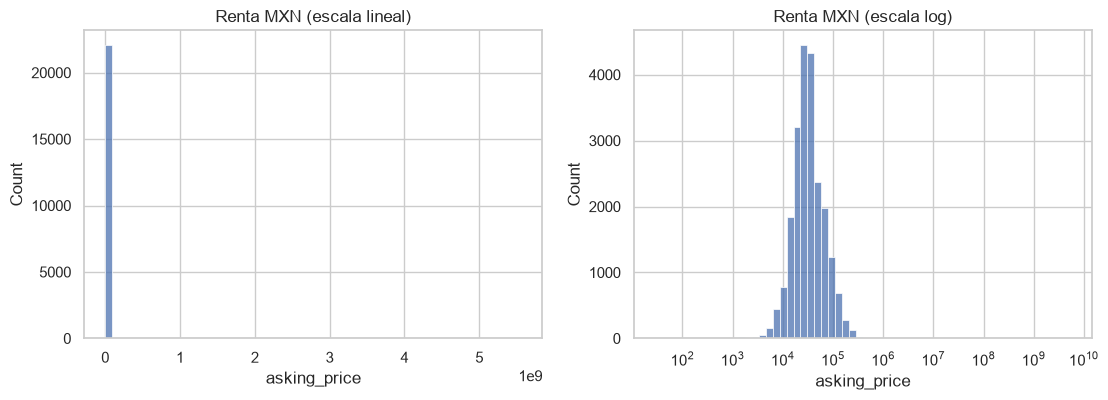

In [16]:
renta_mxn = df.loc[(df['asking_price'] > 0), 'asking_price']

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(renta_mxn, bins=60, ax=axes[0])
axes[0].set_title('Renta MXN (escala lineal)')
sns.histplot(renta_mxn, bins=60, log_scale=True, ax=axes[1])
axes[1].set_title('Renta MXN (escala log)')
plt.show()

En escala lineal no se ve nada por los valores extremos. En escala log la distribución se ve más o menos simétrica alrededor de ~30 mil MXN, con colas a ambos lados que muy probablemente son errores.
Esto sugiere **modelar el logaritmo de la renta** como target mejor

In [17]:
renta_mxn.quantile([0.001, 0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 0.999])

0.00       1,500.00
0.01       6,000.00
0.05      10,000.00
0.25      20,000.00
0.50      31,000.00
0.75      50,000.00
0.95     115,000.00
0.99     204,000.00
1.00   4,183,065.00
Name: asking_price, dtype: float64

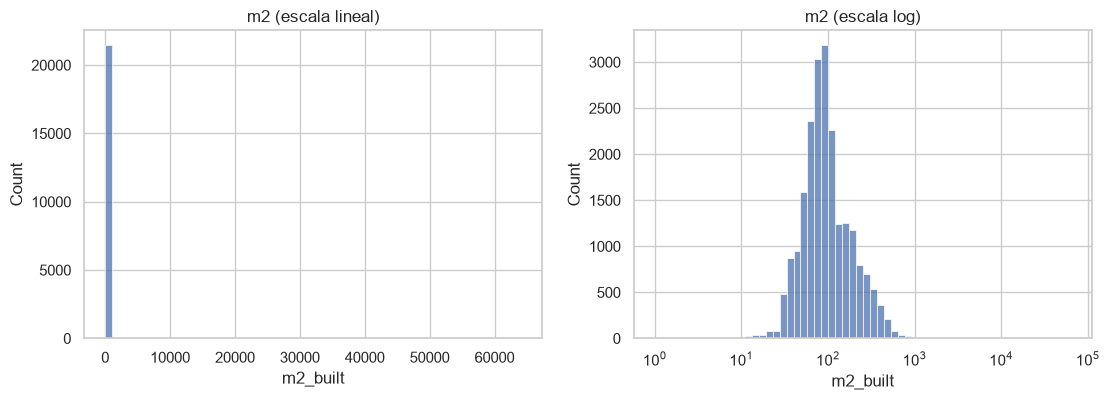

0.00     6.00
0.01    22.00
0.05    37.00
0.50    90.00
0.95   326.00
0.99   505.00
1.00   921.80
Name: m2_built, dtype: float64

In [18]:
m2 = df.loc[df['m2_built'] > 0, 'm2_built']

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(m2, bins=60, ax=axes[0])
axes[0].set_title('m2 (escala lineal)')
sns.histplot(m2, bins=60, log_scale=True, ax=axes[1])
axes[1].set_title('m2 (escala log)')
plt.show()

m2.quantile([0.001, 0.01, 0.05, 0.5, 0.95, 0.99, 0.999])

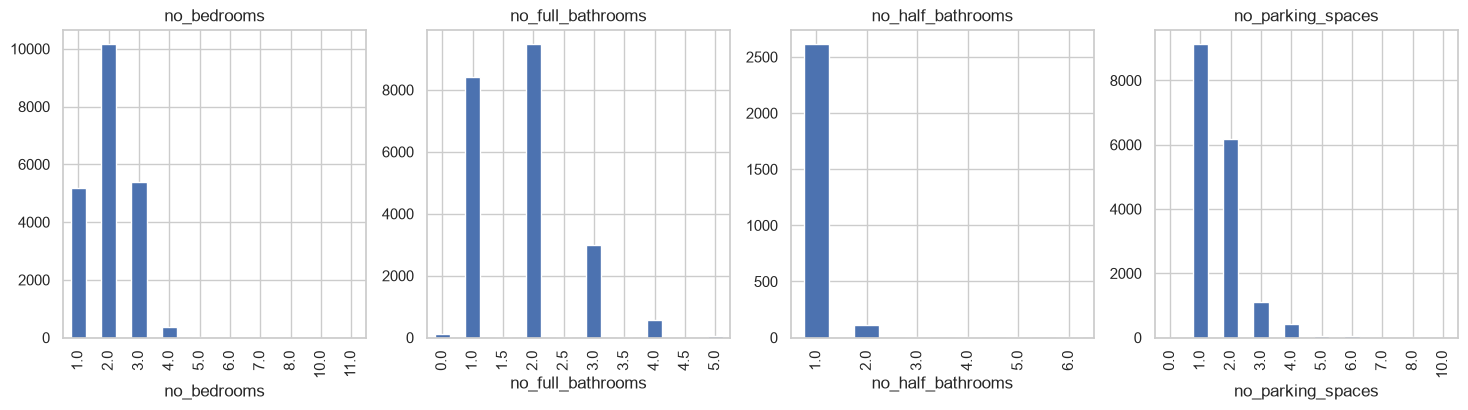

In [19]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))

for ax, c in zip(axes, ['no_bedrooms', 'no_full_bathrooms', 'no_half_bathrooms', 'no_parking_spaces']):
    df[c].value_counts().sort_index().head(10).plot.bar(ax=ax, title=c)

plt.show()

In [20]:
df['del_mun'].value_counts()

del_mun
Miguel Hidalgo            6678
Cuauhtémoc                4919
Benito Juárez             2999
Cuajimalpa de Morelos     2505
Álvaro Obregón            1295
Alvaro Obregón             784
Coyoacán                   743
Tlalpan                    446
Azcapotzalco               414
Gustavo A. Madero          336
Ciudad de México           256
Venustiano Carranza        213
Iztacalco                  185
Iztapalapa                 140
La Magdalena Contreras      96
Xochimilco                  58
Tláhuac                     10
Milpa Alta                   5
otra                         1
Name: count, dtype: int64

In [21]:
print('Mismo id dentro del mismo portal:', df.duplicated(['source_type', 'id']).sum())

# Un mismo depto puede publicarse en varios portales: mismas características, precio y colonia. Esta medida es medio a dedo, 
# habría que probar otras cosas para desduplicar dando ciertos rangos de tolerancia..
cols_dup = ['asking_price', 'm2_built', 'no_bedrooms', 'no_full_bathrooms', 'no_parking_spaces', 'del_mun', 'neighborhood']
print('Mismas características y precio:', df.duplicated(cols_dup).sum())

Mismo id dentro del mismo portal: 66
Mismas características y precio: 4246



## Limpieza de datos

In [22]:
n_inicial = len(df)

In [23]:
n = len(df)
df['del_mun'] = df['del_mun'].replace({'Alvaro Obregón': 'Álvaro Obregón'})
df = df[~df['del_mun'].isin(['Ciudad de México', 'otra'])]
print('Eliminados:', n - len(df))
print('Alcaldías:', df['del_mun'].nunique())

Eliminados: 257
Alcaldías: 16


In [24]:
n = len(df)
df = df.drop_duplicates(['source_type', 'id'])
print('Duplicados por id:', n - len(df))

n = len(df)
df = df.drop_duplicates(cols_dup)
print('Duplicados por características y precio:', n - len(df))

Duplicados por id: 66
Duplicados por características y precio: 4310


In [25]:
n = len(df)
df = df.dropna(subset=['asking_price', 'm2_built', 'no_bedrooms', 'no_full_bathrooms', 'lat', 'lon'])

print('Eliminados:', n - len(df))

df.isna().mean().mul(100).round(1).sort_values(ascending=False).head(5)

Eliminados: 3085


no_half_bathrooms   87.50
no_parking_spaces   19.30
neighborhood         1.40
id                   0.00
operation_type       0.00
dtype: float64

In [26]:
n = len(df)
df = df[
    df['asking_price'].between(3_000, 100_000)
    & df['m2_built'].between(20, 300)
    & (df['no_bedrooms'] <= 4)
    & df['no_full_bathrooms'].between(1, 3)
    & ~(df['no_parking_spaces'] > 4)
]

print('Eliminados:', n - len(df))

Eliminados: 1948


In [27]:
n = len(df)
df['precio_m2'] = df['asking_price'] / df['m2_built']

lim_inf, lim_sup = df['precio_m2'].quantile([0.01, 0.99])

df = df[df['precio_m2'].between(lim_inf, lim_sup)]

print(f'Rango aceptado de precio/m²: {lim_inf:,.0f} – {lim_sup:,.0f} MXN')
print('Eliminados:', n - len(df))

Rango aceptado de precio/m²: 93 – 823 MXN
Eliminados: 250


In [28]:
n = len(df)
df = df[df['lat'].between(19.0, 19.6) & df['lon'].between(-99.4, -98.9)]
print('Eliminados por coordenadas fuera de CDMX:', n - len(df))

Eliminados por coordenadas fuera de CDMX: 13


In [29]:
print(f'Registros: {n_inicial:,} -> {len(df):,} ({len(df) / n_inicial:.0%} conservado)')
df.describe().T

Registros: 22,083 -> 12,154 (55% conservado)


,count,mean,std,min,25%,50%,75%,max
lat,"12,154.00",19.40,0.04,19.21,19.37,19.41,19.43,19.56
lon,"12,154.00",-99.19,0.04,-99.33,-99.21,-99.18,-99.16,-98.97
asking_price,"12,154.00","33,585.58","19,897.18","3,800.00","19,300.00","28,900.00","42,000.00","100,000.00"
m2_built,"12,154.00",103.91,55.75,20.00,65.00,90.00,125.00,300.00
no_bedrooms,"12,154.00",2.00,0.70,1.00,2.00,2.00,2.00,4.00
no_full_bathrooms,"12,154.00",1.74,0.65,1.00,1.00,2.00,2.00,3.00
no_half_bathrooms,"1,239.00",1.02,0.15,1.00,1.00,1.00,1.00,3.00
no_parking_spaces,"9,722.00",1.53,0.61,1.00,1.00,1.00,2.00,4.00
precio_m2,"12,154.00",337.33,134.78,93.02,239.05,317.92,416.67,822.37


### EDA con datos limpios

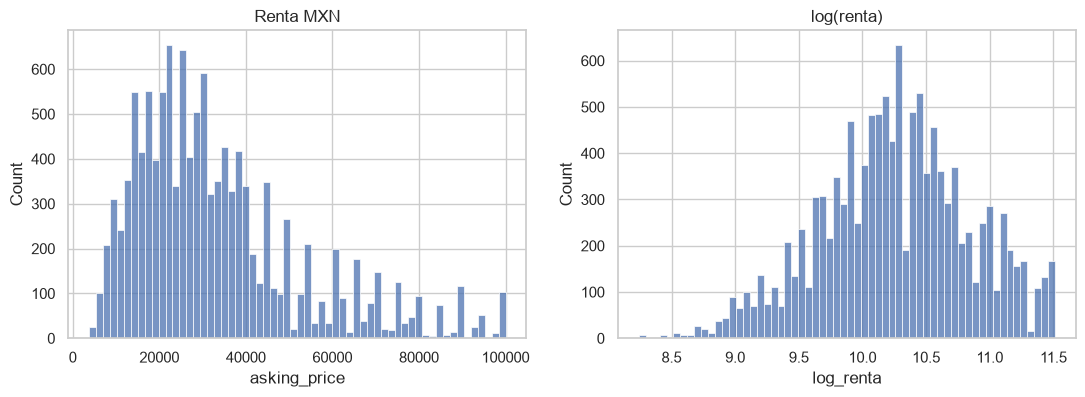

In [30]:
df['log_renta'] = np.log(df['asking_price'])
df['log_m2'] = np.log(df['m2_built'])

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df['asking_price'], bins=60, ax=axes[0])
axes[0].set_title('Renta MXN')
sns.histplot(df['log_renta'], bins=60, ax=axes[1])
axes[1].set_title('log(renta)')
plt.show()

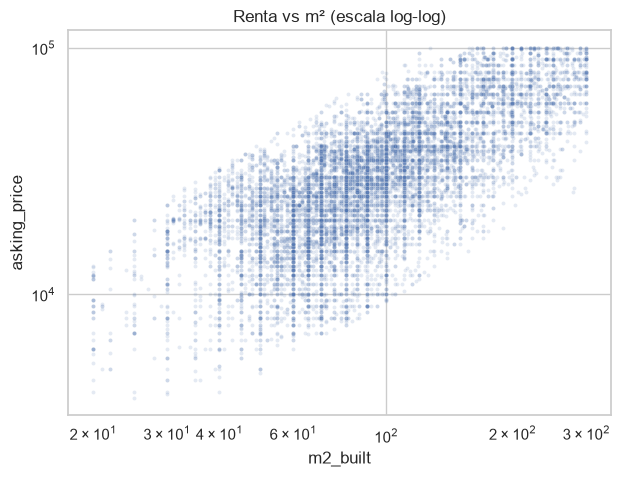

In [31]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(data=df, x='m2_built', y='asking_price', alpha=0.15, s=8, ax=ax)
ax.set(xscale='log', yscale='log', title='Renta vs m² (escala log-log)')
plt.show()

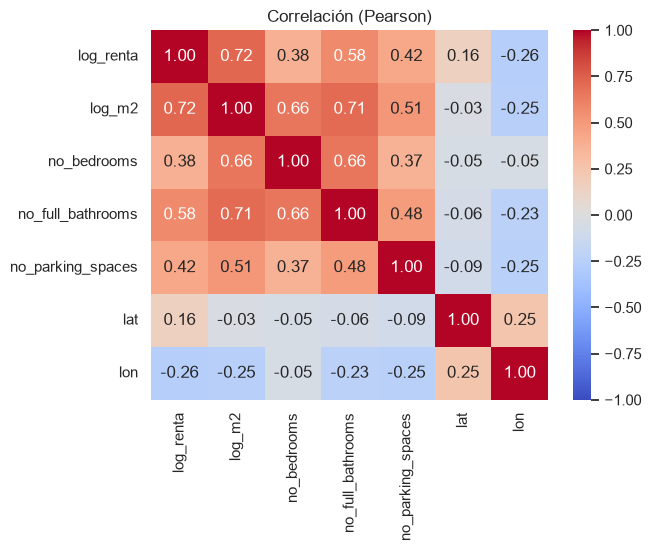

In [32]:
vars_corr = ['log_renta', 'log_m2', 'no_bedrooms', 'no_full_bathrooms', 'no_parking_spaces', 'lat', 'lon']
sns.heatmap(df[vars_corr].corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlación (Pearson)')
plt.show()

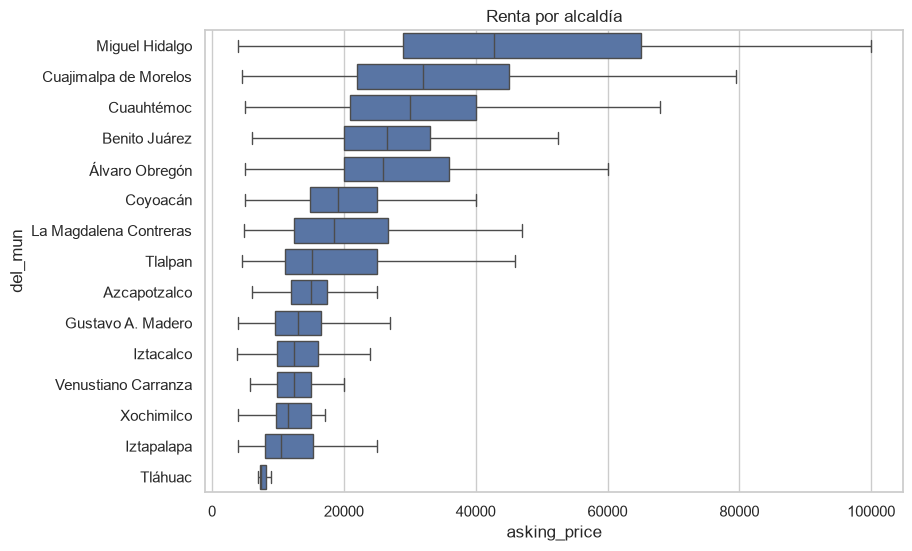

,count,median
del_mun,,
Miguel Hidalgo,3242,"42,800.00"
Cuajimalpa de Morelos,1413,"32,000.00"
Cuauhtémoc,2621,"30,000.00"
Benito Juárez,1925,"26,500.00"
Álvaro Obregón,1282,"26,000.00"
Coyoacán,486,"19,150.00"
La Magdalena Contreras,54,"18,500.00"
Tlalpan,280,"15,125.00"
Azcapotzalco,275,"15,000.00"


In [33]:
orden = df.groupby('del_mun')['asking_price'].median().sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(9, 6))
sns.boxplot(data=df, y='del_mun', x='asking_price', order=orden, showfliers=False, ax=ax)
ax.set_title('Renta por alcaldía')
plt.show()

df.groupby('del_mun')['asking_price'].agg(['count', 'median']).sort_values('median', ascending=False)

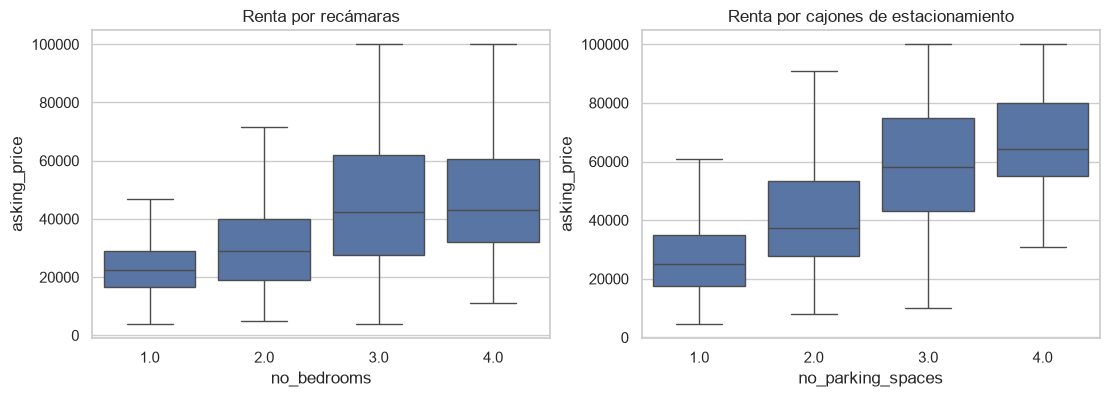

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=df, x='no_bedrooms', y='asking_price', showfliers=False, ax=axes[0])
axes[0].set_title('Renta por recámaras')
sns.boxplot(data=df, x='no_parking_spaces', y='asking_price', showfliers=False, ax=axes[1])
axes[1].set_title('Renta por cajones de estacionamiento')
plt.show()

In [35]:
df.groupby('property_type')['asking_price'].agg(['count', 'median'])

,count,median
property_type,,
Departamento,12125,"28,900.00"
Dúplex,1,"20,000.00"
Estudio,2,"13,000.00"
Loft,22,"18,750.00"
Penthouse,4,"43,750.00"


In [36]:
num_feats = ['m2_built', 'no_bedrooms', 'no_full_bathrooms', 'no_parking_spaces', 'lat', 'lon']
cat_feats = ['del_mun']

X = df[num_feats + cat_feats]
y = df['log_renta']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=df['del_mun'], random_state=SEED)
print('Train:', X_train.shape, '| Test:', X_test.shape)

Train: (8507, 7) | Test: (3647, 7)


In [37]:
rf_params = {'n_estimators': 200, 'min_samples_leaf': 5, 'random_state': SEED, 'n_jobs': -1}

preprocesador = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'), num_feats),
])

modelo = Pipeline([
    ('prep', preprocesador),
    ('reg', RandomForestRegressor(**rf_params)),
])
modelo.fit(X_train, y_train)

dummy = DummyRegressor(strategy='median').fit(X_train, y_train)

In [38]:
modelos = {'Mediana (dummy)': dummy, 'Random Forest': modelo}
real = np.exp(y_test)

resultados = {}
for nombre, m in modelos.items():
    pred_log = m.predict(X_test)
    pred = np.exp(pred_log)
    ape = np.abs(pred - real) / real  # error porcentual absoluto de cada depto
    resultados[nombre] = {
        'MdAPE': np.median(ape),
        'MAPE': mean_absolute_percentage_error(real, pred),
        'PPE20': np.mean(ape <= 0.20),
        'MAE': mean_absolute_error(real, pred),
    }

pd.DataFrame(resultados).T

,MdAPE,MAPE,PPE20,MAE
Mediana (dummy),0.37,0.54,0.29,"14,603.62"
Random Forest,0.15,0.22,0.62,"6,438.82"


In [39]:
# Comparamos con train para detectar sobreajuste
pred_train = np.exp(modelo.predict(X_train))
mdape_train = np.median(np.abs(pred_train - np.exp(y_train)) / np.exp(y_train))

print(f'MdAPE train: {mdape_train:.1%}')
print(f'MdAPE test:  {resultados["Random Forest"]["MdAPE"]:.1%}')

MdAPE train: 11.3%
MdAPE test:  15.2%


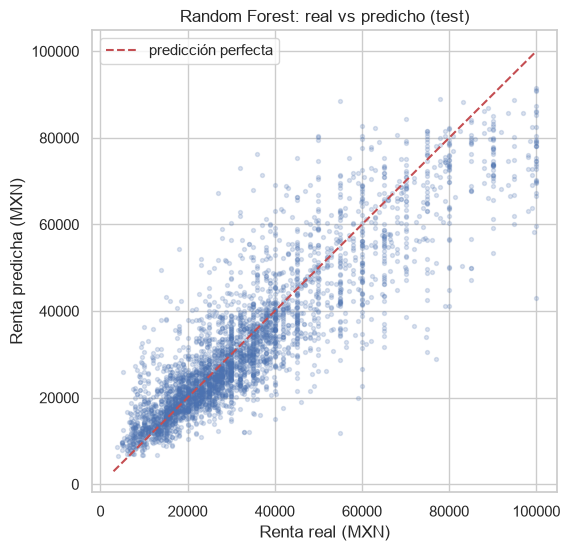

In [40]:
pred_test = np.exp(modelo.predict(X_test))

fig_pred, ax = plt.subplots(figsize=(6, 6))
ax.scatter(real, pred_test, alpha=0.2, s=8)
ax.plot([3000, 100000], [3000, 100000], 'r--', label='predicción perfecta')
ax.set(xlabel='Renta real (MXN)', ylabel='Renta predicha (MXN)',
       title='Random Forest: real vs predicho (test)')
ax.legend()
plt.show()

In [41]:
errores = pd.DataFrame({'real': real, 'pred': pred_test})
errores['error_pct'] = (errores['pred'] - errores['real']).abs() / errores['real']
errores['rango_renta'] = pd.qcut(errores['real'], 5)
errores.groupby('rango_renta', observed=True)['error_pct'].agg(['count', 'median', 'mean'])

,count,median,mean
rango_renta,,,
"(3799.999, 17500.0]",747,0.23,0.40
"(17500.0, 25000.0]",750,0.13,0.18
"(25000.0, 33000.0]",704,0.14,0.18
"(33000.0, 45174.0]",716,0.14,0.18
"(45174.0, 100000.0]",730,0.15,0.18


In [42]:
errores['del_mun'] = X_test['del_mun']
errores.groupby('del_mun')['error_pct'].agg(['count', 'median']).sort_values('median')

,count,median
del_mun,,
Venustiano Carranza,42,0.13
Cuajimalpa de Morelos,424,0.13
Azcapotzalco,83,0.13
Miguel Hidalgo,973,0.14
Álvaro Obregón,385,0.15
Benito Juárez,578,0.16
Cuauhtémoc,786,0.17
Coyoacán,146,0.18
Iztacalco,34,0.18


In [43]:
imp = permutation_importance(
    modelo, X_test[num_feats], y_test, n_repeats=5, random_state=SEED,
    scoring=lambda m, X, y: -100 * np.median(np.abs(np.exp(m.predict(X)) - np.exp(y)) / np.exp(y)),
)

importancias = pd.DataFrame({
    'aumento_MdAPE_pp': imp.importances_mean,
    'std': imp.importances_std,
}, index=num_feats).sort_values('aumento_MdAPE_pp', ascending=False)

importancias

,aumento_MdAPE_pp,std
m2_built,17.92,0.57
lat,9.40,0.38
lon,6.58,0.35
no_full_bathrooms,2.02,0.14
no_bedrooms,0.71,0.03
no_parking_spaces,0.53,0.07


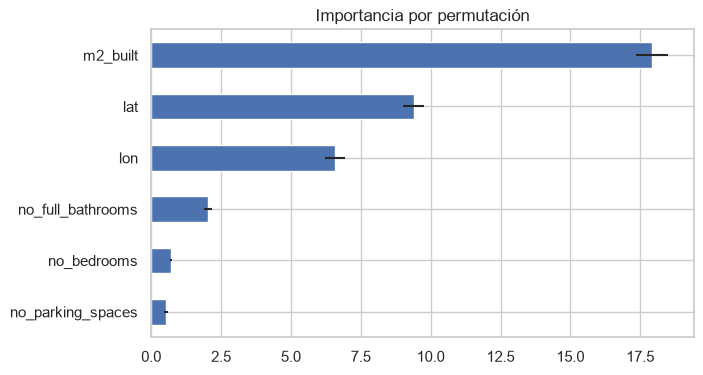

In [44]:
fig_imp, ax = plt.subplots(figsize=(7, 4))
importancias['aumento_MdAPE_pp'].sort_values().plot.barh(xerr=importancias['std'], ax=ax)
ax.set(title='Importancia por permutación')
plt.show()

### Interpretación

**¿Qué tan bueno es el modelo?**

En términos generales, bastante mejor que la referencia. La mitad de los departamentos tiene un error menor a 15% respecto a su renta real (MdAPE), mientras que un modelo "dummy" que siempre predice la mediana se equivoca en 37%. Visto de otra forma, 6 de cada 10 predicciones caen dentro de ±20% de la renta real (PPE20 de 62%), contra apenas 3 de cada 10 del dummy. El error promedio (MAPE) es de 22%, más alto que la mediana. Eso pasa porque hay un grupo de departamentos con errores grandes que jalan el promedio hacia arriba; arriba se ve que estos errores están en los departamentos con rentas más baratas.

Para un departamento de 30 mil pesos, un error típico de ±15% son unos 4,500 pesos. Eso todavía es mucho para fijar el precio exacto de una unidad, pero creo que funciona bien como referencia del rango en el que debería estar.

**¿Hay sobreajuste?**

Un poco. En entrenamiento la MdAPE es de 11.3% y en prueba sube a 15.2%. Esto puede mejorar después haciendo ajuste de hiperparámetros, como poniendo hojas más grandes o limitando la profundidad del árbol. Igual falta hacer algo con cross-validation que quizá pueda ayudar a ver más rondas de datos.

**¿Dónde falla más?**

El modelo batalla sobre todo con las rentas baratas. Por debajo de 17.5 mil pesos, el error mediano es de 23%, mientras que en los demás rangos la mediana se queda alrededor de 13–15%. Hay varias razones: hay menos anuncios baratos, son más heterogéneos y es posible que quede algo de ruido de captura que las reglas de limpieza no detectaron. 

Algo parecido pasa con la ubicación. En las alcaldías con más datos, como Miguel Hidalgo, Cuajimalpa, Álvaro Obregón y Benito Juárez, el error mediano está entre 13 y 16%. Pero en las que tienen pocos anuncios, como Magdalena Contreras, Xochimilco o Tláhuac, se dispara a entre 29 y 56%. Con tan pocos casos, el modelo simplemente no tiene suficientes ejemplos cercanos para aprender cómo se comportan esas zonas.

## Registro en MLFlow

In [45]:
mlflow.set_tracking_uri('http://127.0.0.1:5001')
mlflow.set_experiment('TC5061_Baseline_Rentas_CDMX')

# Parámetros comunes a ambos runs: describen los datos y el split
params = {
    'fuentes': ','.join(fuentes),
    'n_registros': len(df),
    'test_size': 0.3,
    'stratify': 'del_mun',
    'random_state': SEED,
    'target': 'log(asking_price)',
    'features': ','.join(num_feats),
}

In [46]:
with mlflow.start_run(run_name='Mediana (dummy)'):
    mlflow.log_params(params)
    mlflow.log_metrics(resultados['Mediana (dummy)'])

🏃 View run Mediana (dummy) at: http://127.0.0.1:5001/#/experiments/3/runs/b19dcdcbd8a642ec84d8a936391691e0
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/3


In [47]:
with mlflow.start_run(run_name='Random Forest'):
    mlflow.log_params(params)
    mlflow.log_params(rf_params)
    mlflow.log_metrics(resultados['Random Forest'])

    mlflow.log_figure(fig_pred, 'real_vs_predicho.png')
    mlflow.log_figure(fig_imp, 'importancia_permutacion.png')

    mlflow.sklearn.log_model(
        modelo,
        name='modelo',
        input_example=X_train[num_feats].head(5),
        serialization_format='pickle',
    )

2026/10/01 17:39:54 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


🏃 View run Random Forest at: http://127.0.0.1:5001/#/experiments/3/runs/0ae34138d0384868b90b1fc00724342e
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/3


### Evidencia en la interfaz de MLflow

![Experimento en MLflow](mlflow-experimento-baseline1.png)

![Modelos en MLflow](mlflow-experimento-baseline2.png)

## Reflexión

Este flujo funciona, pero depende de que alguien ejecute las celdas en orden y en una sola máquina. Si se aplicaran prácticas de MLOps, hay varias cosas que mejorarían, aunque para mí hay dos que pesan más que las demás.

La primera es la experimentación sistemática. Este modelo es apenas un punto de partida, y lo valioso viene de todo lo que se intente después: ajustar hiperparámetros, probar otros algoritmos, agregar variables nuevas o incorporar otras fuentes de información. Para que esas pruebas sirvan, cada intento tiene que quedar registrado y compararse contra el baseline con el mismo split y la misma métrica. Me interesa en particular explorar el contexto geográfico de cada departamento, no solo las características de la propiedad en sí: qué hay alrededor, qué tan bien conectada está la zona, cómo es el entorno. Hoy las coordenadas capturan parte de eso de forma implícita, pero hacerlo explícito podría mejorar el modelo, sobre todo en las zonas donde hay pocos datos.

La segunda es el monitoreo del modelo una vez que está en uso. El mercado de rentas no se queda quieto: cada cierto número de meses los precios se mueven, y un modelo entrenado con datos de hoy se va quedando atrás poco a poco. Por eso es importante vigilar tanto su error como los cambios en los datos que recibe, y tener claro cuándo toca reentrenarlo para que siempre esté lo más actualizado posible.

Para que todo esto funcione, también hace falta una base más sólida en el manejo de los datos. Los scrapings cambian cada vez que se vuelven a correr, así que conviene versionarlos y saber exactamente con qué datos se entrenó cada modelo. Las reglas de limpieza deberían vivir en un proceso parametrizado y probado, para que los datos nuevos se limpien igual que estos. 

En mi área profesional trabajo con datos inmobiliarios que vienen de fuentes muy distintas: cada portal reporta los campos a su manera y la calidad varía mucho. Este ejercicio confirma que la mayor parte del esfuerzo está en entender y limpiar los datos, y que un modelo sencillo pero bien documentado ya aporta valor como referencia para estimar precios.

Pero quizá el beneficio más grande de tener todo registrado no es técnico, sino de conversación con el negocio. Es común que alguien tenga una idea sobre qué mueve los precios y que, como nadie ha podido mostrarle datos que la confirmen o la descarten, esa creencia termine guiando decisiones durante mucho tiempo. Tener los modelos, los experimentos y sus métricas a la mano permite discutir con el management sobre evidencia: qué se ha intentado, qué funcionó, qué no y cuánto impacto tuvo cada cosa. Sin eso, un análisis que hoy funciona no se puede repetir, auditar ni defender mañana.